In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.preprocessing import RobustScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

from imblearn.over_sampling import SMOTE

import warnings
warnings.filterwarnings("ignore")

## Feature and Target Definition

| Variable | Type | Description |
|----------|------|-------------|
| Time | Feature | Time elapsed (in seconds) since the first transaction in the dataset. |
| V1 – V28 | Feature | PCA-transformed anonymized transaction features. |
| Amount | Feature | Transaction amount. |
| Class | Target | Transaction label: 0 = Normal Transaction, 1 = Fraudulent Transaction. |

### Dataset Summary

- Total Features: 30
- Target Variable: Class
- Normal Transaction (Class = 0)
- Fraudulent Transaction (Class = 1)
- Dataset Type: Binary Classification
- Challenge: Highly Imbalanced Dataset

In [2]:
# Load Dataset
df = pd.read_csv("creditcard.csv")

df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
# DATA OVERVIEW

print("Dataset Shape:")
print(df.shape)

df.info()

Dataset Shape:
(284807, 31)
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float6

In [4]:
# CHECK MISSING VALUES

df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [5]:
# CHECK DUPLICATE RECORDS

duplicate_count = df.duplicated().sum()

print(f"Number of duplicate rows: {duplicate_count}")

Number of duplicate rows: 1081


In [6]:
# REMOVE DUPLICATE RECORDS

df = df.drop_duplicates()

print("New Dataset Shape:", df.shape)

New Dataset Shape: (283726, 31)


In [7]:
# FRAUD VS NON-FRAUD DISTRIBUTION
# 0 = Normal Transaction
# 1 = Fraudulent Transaction

print(df["Class"].value_counts())

Class
0    283253
1       473
Name: count, dtype: int64


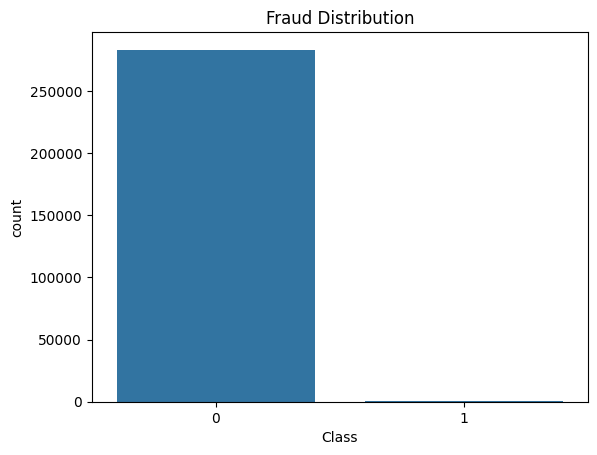

In [8]:
# VISUALIZE CLASS DISTRIBUTION

sns.countplot(x="Class", data=df)

plt.title("Fraud Distribution")

plt.show()

In [9]:
# DEFINE FEATURES AND TARGET

X = df.drop("Class", axis=1)

y = df["Class"]

In [10]:
# TRAIN TEST SPLIT

X = df.drop("Class", axis=1)
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

scaler = RobustScaler()

X_train[['Time', 'Amount']] = scaler.fit_transform(
    X_train[['Time', 'Amount']]
)

X_test[['Time', 'Amount']] = scaler.transform(
    X_test[['Time', 'Amount']]
)

In [11]:
# CREATE MACHINE LEARNING MODELS

model_configs = {

    "Logistic Regression": (
        LogisticRegression(
            random_state=42,
            max_iter=1000
        ),
        {
            "C": [0.1, 1, 10]
        }
    ),

    "Decision Tree": (
        DecisionTreeClassifier(
            random_state=42
        ),
        {
            "max_depth": [5, 10, 15],
            "min_samples_split": [2, 5, 10]
        }
    ),

    "Random Forest": (
        RandomForestClassifier(
            random_state=42,
            n_jobs=-1
        ),
        {
            "n_estimators": [100, 200],
            "max_depth": [10, 15]
        }
    ),

    "XGBoost": (
        XGBClassifier(
            random_state=42,
            eval_metric="logloss"
        ),
        {
            "n_estimators": [100, 200],
            "max_depth": [4, 6],
            "learning_rate": [0.05, 0.1]
        }
    )
}

In [12]:
# TRAIN MODELS ON ORIGINAL DATA

results_original = []

for name, (model, params) in model_configs.items():

    print(f"Tuning {name}...")

    grid = GridSearchCV(
        estimator=model,
        param_grid=params,
        cv=3,
        scoring="f1",
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    model = grid.best_estimator_

    print("Best Params:", grid.best_params_)

    y_pred = model.predict(X_test)

    y_prob = model.predict_proba(X_test)[:, 1]

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    y_prob = model.predict_proba(X_test)[:,1]

    results_original.append({

        "Model": name,
        "Dataset": "Original",

        "Accuracy":
        accuracy_score(y_test, y_pred),

        "Precision":
        precision_score(y_test, y_pred),

        "Recall":
        recall_score(y_test, y_pred),

        "F1":
        f1_score(y_test, y_pred),

        "ROC_AUC":
        roc_auc_score(y_test, y_prob)
    })

Tuning Logistic Regression...
Best Params: {'C': 1}
Tuning Decision Tree...
Best Params: {'max_depth': 5, 'min_samples_split': 2}
Tuning Random Forest...
Best Params: {'max_depth': 15, 'n_estimators': 200}
Tuning XGBoost...
Best Params: {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 200}


In [13]:
# RESULTS ON ORIGINAL DATA

original_df = pd.DataFrame(results_original)

original_df

,Model,Dataset,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,Original,0.999154,0.861538,0.589474,0.700000,0.957516
1,Decision Tree,Original,0.999348,0.881579,0.705263,0.783626,0.906045
2,Random Forest,Original,0.999542,0.985915,0.736842,0.843373,0.971791
3,XGBoost,Original,0.999471,0.945205,0.726316,0.821429,0.975023


In [14]:
# APPLY SMOTE TO BALANCE DATA

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

In [15]:
# CHECK CLASS DISTRIBUTION AFTER SMOTE

print("Before SMOTE")

print(y_train.value_counts())

print()

print("After SMOTE")

print(y_train_smote.value_counts())

Before SMOTE
Class
0    226602
1       378
Name: count, dtype: int64

After SMOTE
Class
0    226602
1    226602
Name: count, dtype: int64


In [16]:
# TRAIN MODELS ON SMOTE DATA

results_smote = []

for name, (model, params) in model_configs.items():

    print(f"Tuning {name}...")

    grid = GridSearchCV(
        estimator=model,
        param_grid=params,
        cv=3,
        scoring="f1",
        n_jobs=-1
    )

    grid.fit(
        X_train_smote,
        y_train_smote
    )

    model = grid.best_estimator_

    print("Best Params:", grid.best_params_)

    y_pred = model.predict(X_test)

    y_prob = model.predict_proba(X_test)[:, 1]

    model.fit(
        X_train_smote,
        y_train_smote
    )

    y_pred = model.predict(X_test)

    y_prob = model.predict_proba(X_test)[:,1]

    results_smote.append({

        "Model": name,
        "Dataset": "SMOTE",

        "Accuracy":
        accuracy_score(y_test, y_pred),

        "Precision":
        precision_score(y_test, y_pred),

        "Recall":
        recall_score(y_test, y_pred),

        "F1":
        f1_score(y_test, y_pred),

        "ROC_AUC":
        roc_auc_score(y_test, y_prob)
    })

Tuning Logistic Regression...
Best Params: {'C': 10}
Tuning Decision Tree...
Best Params: {'max_depth': 15, 'min_samples_split': 2}
Tuning Random Forest...
Best Params: {'max_depth': 15, 'n_estimators': 100}
Tuning XGBoost...
Best Params: {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 200}


In [17]:
# RESULTS ON SMOTE DATA

smote_df = pd.DataFrame(results_smote)

smote_df

,Model,Dataset,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,SMOTE,0.973954,0.053583,0.873684,0.100973,0.960010
1,Decision Tree,SMOTE,0.995365,0.229032,0.747368,0.350617,0.822286
2,Random Forest,SMOTE,0.999260,0.773196,0.789474,0.781250,0.974858
3,XGBoost,SMOTE,0.999137,0.716981,0.800000,0.756219,0.968096


In [18]:
# COMBINE ALL RESULTS

final_results = pd.concat(
    [original_df, smote_df],
    ignore_index=True
)

final_results

,Model,Dataset,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,Original,0.999154,0.861538,0.589474,0.700000,0.957516
1,Decision Tree,Original,0.999348,0.881579,0.705263,0.783626,0.906045
2,Random Forest,Original,0.999542,0.985915,0.736842,0.843373,0.971791
3,XGBoost,Original,0.999471,0.945205,0.726316,0.821429,0.975023
4,Logistic Regression,SMOTE,0.973954,0.053583,0.873684,0.100973,0.960010
5,Decision Tree,SMOTE,0.995365,0.229032,0.747368,0.350617,0.822286
6,Random Forest,SMOTE,0.999260,0.773196,0.789474,0.781250,0.974858
7,XGBoost,SMOTE,0.999137,0.716981,0.800000,0.756219,0.968096


In [19]:
# SORT RESULTS BY F1 SCORE

final_results = final_results.sort_values(
    by="F1",
    ascending=False
)

final_results

,Model,Dataset,Accuracy,Precision,Recall,F1,ROC_AUC
2,Random Forest,Original,0.999542,0.985915,0.736842,0.843373,0.971791
3,XGBoost,Original,0.999471,0.945205,0.726316,0.821429,0.975023
1,Decision Tree,Original,0.999348,0.881579,0.705263,0.783626,0.906045
6,Random Forest,SMOTE,0.999260,0.773196,0.789474,0.781250,0.974858
7,XGBoost,SMOTE,0.999137,0.716981,0.800000,0.756219,0.968096
0,Logistic Regression,Original,0.999154,0.861538,0.589474,0.700000,0.957516
5,Decision Tree,SMOTE,0.995365,0.229032,0.747368,0.350617,0.822286
4,Logistic Regression,SMOTE,0.973954,0.053583,0.873684,0.100973,0.960010


In [20]:
# IDENTIFY BEST MODEL

best_model = final_results.iloc[0]

best_model

Model        Random Forest
Dataset           Original
Accuracy          0.999542
Precision         0.985915
Recall            0.736842
F1                0.843373
ROC_AUC           0.971791
Name: 2, dtype: object

# 🏆 Best Model Selection

## Primary Evaluation Metric: F1-Score

F1-Score was selected as the primary evaluation metric because it provides a balanced assessment of both **Precision** and **Recall**, which are critical in fraud detection tasks.

- **Precision** measures how many transactions predicted as fraud are actually fraudulent.
- **Recall** measures how many fraudulent transactions are correctly identified.
- **F1-Score** combines Precision and Recall into a single metric, making it particularly suitable for **highly imbalanced datasets** such as credit card fraud detection.

| Rank | Model | Dataset | F1-Score |
|---------|---------|---------|---------|
| 🥇 1 | Random Forest | Original | **0.843** |
| 🥈 2 | XGBoost | Original | **0.821** |
| 🥉 3 | Decision Tree | Original | **0.784** |
| 4 | Random Forest | SMOTE | **0.781** |
| 5 | XGBoost | SMOTE | **0.756** |
| 6 | Logistic Regression | Original | **0.700** |
| 7 | Decision Tree | SMOTE | **0.351** |
| 8 | Logistic Regression | SMOTE | **0.101** |


---

## Hyperparameter Optimization using GridSearchCV

To improve model performance and ensure a fair comparison, **GridSearchCV with Cross Validation** was applied to all machine learning models.

### Purpose of GridSearchCV

- Automatically search for the best combination of hyperparameters.
- Reduce manual trial-and-error tuning.
- Improve model generalization performance.
- Minimize overfitting through cross-validation.

### Cross Validation

A **3-Fold Cross Validation** strategy was used during Grid Search:

```text
Training Data
      ↓
  3-Fold CV
      ↓
GridSearchCV
      ↓
Best Hyperparameters
      ↓
Optimized Model
```

This approach ensures that model performance is evaluated across multiple training-validation splits before selecting the final hyperparameter configuration.

---

## Model Comparison Result

After applying GridSearchCV and evaluating all optimized models on both the Original Dataset and the SMOTE-balanced Dataset, the following results were obtained:

| Model | Dataset | Accuracy | Precision | Recall | F1-Score | ROC-AUC |
|---------|---------|---------|---------|---------|---------|---------|
| **Random Forest** | **Original** | **0.999542** | **0.985915** | **0.736842** | **0.843373** | **0.971791** |
| XGBoost | Original | 0.999471 | 0.945205 | 0.726316 | 0.821429 | 0.975023 |
| Decision Tree | Original | 0.999348 | 0.881579 | 0.705263 | 0.783626 | 0.906045 |
| Random Forest | SMOTE | 0.999260 | 0.773196 | 0.789474 | 0.781250 | 0.974858 |
| XGBoost | SMOTE | 0.999137 | 0.716981 | 0.800000 | 0.756219 | 0.968096 |
| Logistic Regression | Original | 0.999154 | 0.861538 | 0.589474 | 0.700000 | 0.957516 |
| Decision Tree | SMOTE | 0.995365 | 0.229032 | 0.747368 | 0.350617 | 0.822286 |
| Logistic Regression | SMOTE | 0.973954 | 0.053583 | 0.873684 | 0.100973 | 0.960010 |

---

## Best Performing Model

✅ **Random Forest trained on the Original Dataset achieved the highest F1-Score (0.843373).**

Therefore, **Random Forest (Original Dataset)** was selected as the final model for this fraud detection project.

---

## Key Findings

### Random Forest

- Achieved the highest overall F1-Score (**0.843373**).
- Produced the best balance between Precision (**0.985915**) and Recall (**0.736842**).
- Maintained excellent fraud detection capability while keeping false-positive predictions extremely low.

### XGBoost

- Achieved competitive performance with an F1-Score of **0.821429**.
- Produced the highest ROC-AUC score (**0.975023**).
- Slightly underperformed compared to Random Forest in terms of F1-Score.

### Effect of SMOTE

- SMOTE increased Recall for several models.
- However, Precision decreased substantially after oversampling.
- Consequently, the overall F1-Score decreased for both Random Forest and XGBoost.

### Logistic Regression and Decision Tree

- Performed worse than ensemble-based models.
- Applying SMOTE caused a significant drop in Precision, leading to lower F1-Scores.

---

## Discussion

Although SMOTE is commonly used to address class imbalance, the results indicate that it did not improve the overall performance of the strongest models in this study.

For the Credit Card Fraud Detection dataset, Random Forest and XGBoost were able to learn fraud patterns effectively from the original training data without relying on synthetic samples. While SMOTE increased Recall, the corresponding reduction in Precision led to lower F1-Scores.

These findings suggest that ensemble-based models can effectively handle fraud detection tasks on this dataset without requiring oversampling techniques.

---

## Final Selected Model

> 🌟 **Random Forest (Original Dataset)**  
>
> **Accuracy:** 99.95%  
> **Precision:** 98.59%  
> **Recall:** 73.68%  
> **F1-Score:** 84.34%  
> **ROC-AUC:** 97.18%

---

## Final Conclusion

✅ GridSearchCV was used to optimize the hyperparameters of all machine learning models through Cross Validation.

✅ Random Forest achieved the highest F1-Score among all evaluated models.

✅ The Original Dataset outperformed the SMOTE-balanced Dataset for the best-performing models.

✅ Random Forest (Original Dataset) was selected as the final fraud detection model due to its superior balance between Precision and Recall and its highest overall F1-Score.